# code_039 · Time-aware information availability

**Book:** section 8.3. A dataset-construction laboratory using invented structural-monitoring records. Prerequisites: Python arrays, tables and Chapter 7's information boundaries. Restart and run all cells. Every import, helper and input is here; no ordinary-run files, network, credentials, GPU or private helper are required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_08_GUIDE.md), [run evidence](../CHAPTER_08_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_039).

Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0, CPU. Allow one minute to execute and 30–60 minutes to interpret. These are scoped data-contract experiments rather than exhaustive estimator API studies. Construction identities have no training/test interpretation. The sampling laboratory alone fits two fixed constant predictors and protects an independent final population. No engineering reliability or causal maintenance conclusion follows.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=839;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 839


<a id="versions"></a>
## Version history is part of the input

Three members have measurement events on days 2,6,10; member 2 has only the first event. Each event has an original value arriving one day later and a corrected value arriving eight days later. A separate event on day 4 arrives on day 12. Cutoffs 0,5,9,13 ask what was known then. Keys are (measurement_id,arrival_day); the generator has no simultaneous competing versions. An operational system would need a deterministic version tie-break and timezone contract.

Rule: per cutoff discard events and versions not yet available; retain latest arrived version per measurement; then match latest event per member backward with tolerance five days. A correction to an older event must not replace a newer available event. Missing and stale history remain missing. This is a point-in-time feature assembly audit, not a fitted forecasting model.


In [2]:
rows=[]
for m in range(3):
 for e in ([2] if m==2 else [2,6,10]):
  mid=f'm{m}-e{e}';rows.extend([(mid,m,e,e+1,.1*m+.01*e),(mid,m,e,e+8,.1*m+.01*e+5)])
 rows.append((f'm{m}-late',m,4,12,.1*m+9))
versions=pd.DataFrame(rows,columns=['measurement_id','member_id','event_day','arrival_day','value_mm'])
assert not versions.duplicated(['measurement_id','arrival_day']).any()
queries=pd.MultiIndex.from_product([[0,5,9,13],range(3)],names=['cutoff_day','member_id']).to_frame(index=False)
queries['case_id']=np.arange(len(queries))
def assemble(source):
 pieces=[]
 for t,query in queries.groupby('cutoff_day',sort=True):
  eligible=source[(source.event_day<=t)&(source.arrival_day<=t)]
  current=eligible.sort_values('arrival_day').drop_duplicates('measurement_id',keep='last')
  right=current.sort_values(['event_day','measurement_id'])
  out=pd.merge_asof(query.sort_values('cutoff_day'),right,left_on='cutoff_day',right_on='event_day',by='member_id',direction='backward',tolerance=5)
  pieces.append(out)
 return pd.concat(pieces).sort_values('case_id').reset_index(drop=True)
clean=assemble(versions);valid=clean.value_mm.notna()
assert len(clean)==len(queries) and clean.case_id.is_unique
assert (clean.loc[valid,'event_day']<=clean.loc[valid,'cutoff_day']).all()
assert (clean.loc[valid,'arrival_day']<=clean.loc[valid,'cutoff_day']).all()
assert (clean.loc[valid,'cutoff_day']-clean.loc[valid,'event_day']<=5).all()
assert clean.loc[clean.cutoff_day==0,'value_mm'].isna().all()
assert clean.loc[(clean.member_id==2)&(clean.cutoff_day==13),'value_mm'].isna().all()


<a id="timeline"></a>
## The label horizon is later than the feature cutoff

The figure is an explicit day-scale fixture: an event at day 2 arrives at day 3; its correction arrives day 10. At cutoff day 5 the original version is eligible, but the correction is not. A target window (5,12] and label report at 14 belong to the outcome path. An event timestamp alone is not a record of historical knowledge.


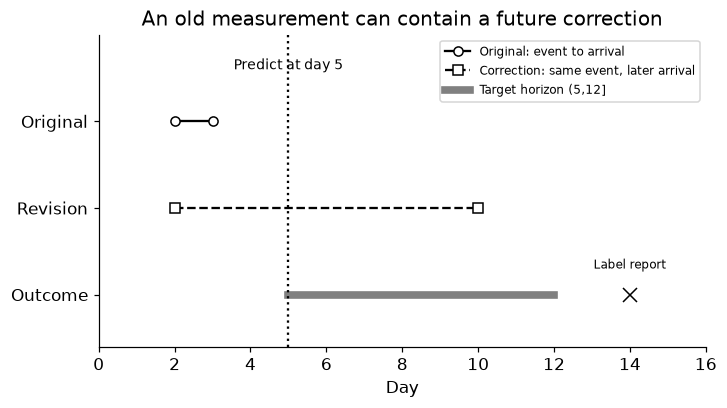

In [3]:
fig,ax=plt.subplots(figsize=(6.5,3.6));ax.plot([2,3],[2,2],'k-o',mfc='white',label='Original: event to arrival');ax.plot([2,10],[1,1],'k--s',mfc='white',label='Correction: same event, later arrival');ax.plot([5,12],[0,0],color='.5',lw=5,label='Target horizon (5,12]');ax.plot(14,0,'kx',ms=9);ax.text(14,.3,'Label report',ha='center',fontsize=8);ax.axvline(5,color='black',ls=':');ax.text(5,2.6,'Predict at day 5',ha='center',fontsize=9);ax.set(xlim=(0,16),ylim=(-.6,3),yticks=[0,1,2],yticklabels=['Outcome','Revision','Original'],xlabel='Day',title='An old measurement can contain a future correction');ax.legend(fontsize=8,loc='upper right');plt.show()
RESULTS['historical_cases']=len(clean);RESULTS['valid_cases']=int(valid.sum());RESULTS['missing_or_stale_cases']=int((~valid).sum())


<a id="invariance"></a>
## A future append must not rewrite historical features

An event-only join against the current revised table selects versions uploaded after the historical cutoff. Construct it as an invalid counterexample. Append a future revision with value 999 mm and arrival day 40: proper past features remain exactly equal, including missingness. This metamorphic check protects a mechanism rather than restating row counts. Availability filtering precedes version resolution; version resolution precedes event matching. Backward as-of by itself handles only one matching clock.


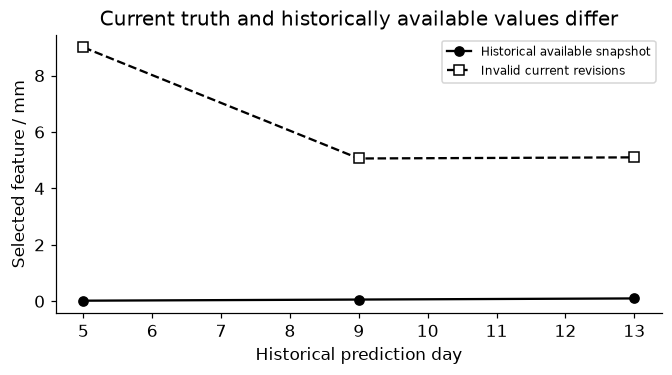

,case_id,member_id,cutoff_day,event_day,arrival_day,value_mm
0,0,0,0,NaN,NaN,NaN
1,1,1,0,NaN,NaN,NaN
2,2,2,0,NaN,NaN,NaN
3,3,0,5,2.0,3.0,0.02
4,4,1,5,2.0,3.0,0.12
5,5,2,5,2.0,3.0,0.22
6,6,0,9,6.0,7.0,0.06
7,7,1,9,6.0,7.0,0.16
8,8,2,9,NaN,NaN,NaN
9,9,0,13,10.0,11.0,0.10


In [4]:
latest=versions.sort_values('arrival_day').drop_duplicates('measurement_id',keep='last').sort_values(['event_day','measurement_id'])
naive=pd.merge_asof(queries.sort_values('cutoff_day'),latest,left_on='cutoff_day',right_on='event_day',by='member_id',direction='backward',tolerance=5).sort_values('case_id')
invalid=naive.value_mm.notna()&(naive.arrival_day>naive.cutoff_day)
assert invalid.any()
future=pd.DataFrame([('m0-e2',0,2,40,999.)],columns=versions.columns)
replayed=assemble(pd.concat([versions,future],ignore_index=True))
assert clean.equals(replayed)
assert clean.loc[(clean.member_id==0)&(clean.cutoff_day==5),'value_mm'].iloc[0]==.02
assert clean.loc[(clean.member_id==0)&(clean.cutoff_day==13),'value_mm'].iloc[0]==.10
fig,ax=plt.subplots(figsize=(6,3.3));a=clean[clean.member_id==0];b=naive[naive.member_id==0];ax.plot(a.cutoff_day,a.value_mm,'ko-',label='Historical available snapshot');ax.plot(b.cutoff_day,b.value_mm,'ks--',mfc='white',label='Invalid current revisions');ax.set(xlabel='Historical prediction day',ylabel='Selected feature / mm',title='Current truth and historically available values differ');ax.legend(fontsize=8);plt.show()
RESULTS['invalid_current_revision_cases']=int(invalid.sum());RESULTS['future_append_preserves_past']=True;RESULTS['member0_features_days5_9_13']=clean[(clean.member_id==0)&(clean.cutoff_day>0)].value_mm.tolist()
display(clean[['case_id','member_id','cutoff_day','event_day','arrival_day','value_mm']])


<a id="exercises"></a>
## Exercises, hints and troubleshooting

1. Upload a newer event late. Verify that eligibility and event recency are separate orderings.
2. Change staleness tolerance from 5 to 2 days. Predict which cases become unavailable before running.
3. Add conflicting versions with equal arrival time and require an explicit revision sequence before accepting them.
4. Reconstruct labels at a training cutoff using the report clock from section 8.1.

**Hints:** preserve immutable versions, UTC-aware timestamps, record identity and source IDs. Do not forward-fill a measurement indefinitely or overwrite earlier snapshots with corrected values. [merge_asof](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html) requires ascending match keys; grouping and backward matching do not implement a second availability clock automatically. No transductive/future-input access is assumed here.


In [5]:
summary={'example_id':'code_039','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['event arrival and prediction clocks', 'revision-aware historical snapshots', 'backward as-of matching after eligibility filtering', 'staleness and missing-history contracts', 'future revision invariance'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["event arrival and prediction clocks", "revision-aware historical snapshots", "backward as-of matching after eligibility filtering", "staleness and missing-history contracts", "future revision invariance"], "elapsed_seconds": 0.15, "example_id": "code_039", "hardware": "Darwin arm64 CPU", "results": {"future_append_preserves_past": true, "historical_cases": 12, "invalid_current_revision_cases": 8, "member0_features_days5_9_13": [0.02, 0.06, 0.1], "missing_or_stale_cases": 5, "valid_cases": 7}, "seed": 839, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
